In [1]:
import pandas as pd
from pathlib import Path

RAW_DATA_DIR = Path.cwd().parent / "data" / "raw"

In [2]:
TRAIN_DIR = RAW_DATA_DIR / "seg_train"
class_counts = {
    folder.name: len(list(folder.iterdir()))
    for folder in TRAIN_DIR.iterdir()
    if folder.is_dir()
}

class_distribution = pd.DataFrame.from_dict(class_counts, orient="index", columns=["image_count"])
class_distribution["percentage"] = (( class_distribution["image_count"] / class_distribution["image_count"].sum()) * 100).round(3)
print(class_distribution)

print(class_distribution["image_count"].sum())

           image_count  percentage
buildings         2628      15.428
forest            2745      16.115
glacier           2957      17.359
mountain          3037      17.829
sea               2784      16.344
street            2883      16.925
17034


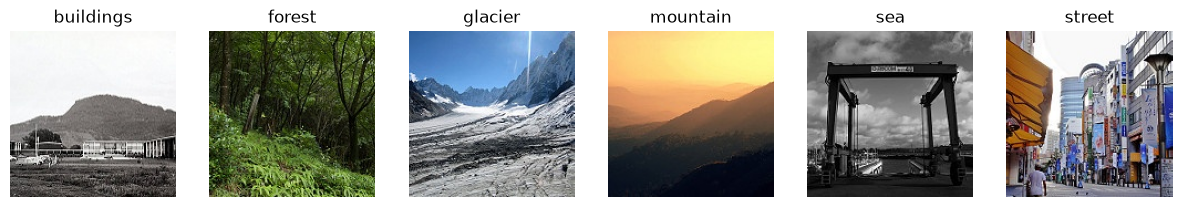

In [3]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(1, 6, figsize=(15, 3))

for ax, folder in zip(axes, sorted(TRAIN_DIR.iterdir())):
    if folder.is_dir():
        image_path = next(folder.iterdir())
        ax.imshow(Image.open(image_path))
        ax.set_title(folder.name)
        ax.axis("off")

plt.show()

In [4]:
from collections import Counter

dimensions = Counter()
formats = Counter()

for folder in TRAIN_DIR.iterdir():
    if folder.is_dir():
        for file in folder.iterdir():
            if file.suffix.lower() in {".jpg", ".jpeg", ".png"}:
                with Image.open(file) as img:
                    dimensions[img.size] += 1
                    formats[img.format] += 1

print("Dimensions:", dimensions)
print("Formats:", formats)

Dimensions: Counter({(150, 150): 16979, (150, 113): 7, (150, 135): 3, (150, 111): 3, (150, 108): 2, (150, 141): 2, (150, 136): 2, (150, 110): 2, (150, 149): 2, (150, 143): 2, (150, 146): 2, (150, 134): 2, (150, 142): 2, (150, 123): 2, (150, 76): 2, (150, 144): 2, (150, 131): 2, (150, 81): 2, (150, 124): 1, (150, 133): 1, (150, 115): 1, (150, 105): 1, (150, 120): 1, (150, 119): 1, (150, 102): 1, (150, 72): 1, (150, 97): 1, (150, 103): 1, (150, 100): 1, (150, 145): 1, (150, 147): 1, (150, 140): 1})
Formats: Counter({'JPEG': 17034})


In [ ]:
corrupted_images = []

for folder in TRAIN_DIR.iterdir():
    if folder.is_dir():
        for file in folder.iterdir():
            if file.is_file() and file.suffix.lower() in {".jpg", ".jpeg", ".png"}:
                try:
                    with Image.open(file) as img:
                        img.verify()
                except Exception:
                    corrupted_images.append(file)

print("Corrupted images:", len(corrupted_images))

Corrupted images: 0


In [6]:
from sklearn.model_selection import train_test_split

data = []

for folder in TRAIN_DIR.iterdir():
    if folder.is_dir():
        for file in folder.iterdir():
            if file.is_file() and file.suffix.lower() == ".jpg":
                data.append({"path": str(file), "label": folder.name})

df = pd.DataFrame(data)

train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=42
)

val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=42
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 11923
Validation: 2555
Test: 2556


In [8]:
combined_df = pd.concat([
    train_df.assign(split="Train"),
    val_df.assign(split="Validation"),
    test_df.assign(split="Test")
])

pd.crosstab(combined_df["split"], combined_df["label"])

label,buildings,forest,glacier,mountain,sea,street
split,,,,,,
Test,394,412,444,456,417,433
Train,1839,1921,2070,2126,1949,2018
Validation,395,412,443,455,418,432


Train	    70%	The model learns by updating its weights using these images.
Validation	15%	You monitor performance and tune the model during development.
Test    	15%	You evaluate the final model on images not used for training or model selection.